# Week 43, Monday lecture: one equation three ways, reading a classifier, and the first hour of convolutional networks

**FYS-STK3155/4155, Monday October 19, 2026**

This notebook contains the code behind every figure and number in the Monday
slides (`week43slides.pdf`). It follows the lecture.

*Part 1* repeats the differential-equation method of week 42 on one equation,
the one-dimensional Poisson equation $-g''=f$ of Section 9.5, and solves it
three ways: with the trial solution $g_t=x(1-x)N(x)$ that carries the
boundary conditions exactly (hard constraints, Eq. 9.18), with a
physics-informed network whose boundary conditions are penalty terms in the
cost (soft constraints, Section 9.10), and with the classical finite-difference
scheme of Eqs. (9.21)–(9.22), whose tridiagonal system is solved by Thomas'
algorithm in $O(n)$ operations. The network code is the one of weeks 41 and
42, unchanged.

*Part 2* is about reading the output of a binary classifier (Section 5.12):
the four counts of the confusion matrix and what every measure made from
them *means* — accuracy and why it misleads, precision, recall, specificity,
$F_1$, balanced accuracy, MCC — on a worked screening example; the ROC curve
and the AUC as a probability about pairs; the precision–recall curve; why
we train on the cross entropy; the choice of threshold; and the ten-class
confusion matrix that Project 2 asks for. The classifiers are those of Project 2 — logistic regression (the
week-41 network with no hidden layer) and a network with one hidden layer —
on the full MNIST set with "is the digit a five?" as the question. Every
metric is implemented by hand and checked against `scikit-learn`.

*Part 3* opens Chapter 10 (Sections 10.1–10.3) with the pieces of a
convolutional network that fit in a few lines: convolution as polynomial
multiplication and as a Toeplitz matrix, the two-dimensional
cross-correlation of a digit with three fixed filters, and the parameter
count of Eq. (10.18). Equivariance and pooling follow next week.

The functions are the ones in `make_week43_figures.py` (which imports
`make_week41_figures.py` and `make_week42_figures.py`); the seeds are 2026
for the classifiers and 1 for the Poisson networks, so that the figures here
are the figures on the slides. Running everything takes about a minute. As
in week 42, the Adam-trained Poisson numbers of Part 1 depend slightly on
the platform (CPU, JAX version); the classifier numbers of Part 2 do not.

**Before you start:** the solutions to the exercises of weeks 41 and 42 are
in the weekly material folders of the course repository,
[`doc/WeeklyMaterial/week41`](https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week41)
and
[`doc/WeeklyMaterial/week42`](https://github.com/EducationalMaterialUiO/MachineLearningUiO/tree/main/doc/WeeklyMaterial/week42)
(`exercisesweek41_solutions.ipynb`, `exercisesweek42_solutions.ipynb`).
Compare with your own solutions after you have made them; the code is yours
to reuse in Project 2 provided you can explain every line.

The weekly exercises (`exercisesweek43.ipynb`, deadline **Friday October
23**) do Part 2 on data of your own; the Tuesday session does the same steps
on the small digits set.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp

BLUE, RED, YELLOW, GREY = "#004488", "#BB5566", "#DDAA33", "#777777"
GREEN = "#228833"
np.set_printoptions(precision=4, suppress=True)

## The network of weeks 41 and 42, unchanged

The cells below are the week-41 network (activations, `create_layers`,
`feed_forward`, `backpropagation`, `train`, the three output heads) and the
week-42 additions for differential equations (the forward pass in
`jax.numpy`, `d_dxk` for derivatives with respect to the input, Adam on any
pytree, `solve_de` and `pinn_solve`). They are reproduced verbatim so that
the notebook runs on its own; nothing in them is new this week.

In [2]:
def sigmoid(z):
    """The logistic function, Eq. (8.22), evaluated without overflow."""
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def sigmoid_prime(z):
    s = sigmoid(z)
    return s * (1.0 - s)


def relu(z):
    """Eq. (8.23)."""
    return np.maximum(0.0, z)


def relu_prime(z):
    return (z > 0).astype(float)


def identity(z):
    return z


def identity_prime(z):
    return np.ones_like(z)


def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)



ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_prime),
               "relu": (relu, relu_prime),
               "identity": (identity, identity_prime)}

OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax}


def tanh(z):
    """tanh(z) = 2 sigma(2z) - 1, Section 8.6.1: centred on zero, derivative up to 1."""
    return np.tanh(z)


def tanh_prime(z):
    return 1.0 - np.tanh(z) ** 2



ACTIVATIONS["tanh"] = (tanh, tanh_prime)

In [3]:
def create_layers(sizes, hidden_activation="sigmoid", rng=None):
    """A list of (W, b) pairs, W of shape (inputs, outputs) as in the template.

    sizes = [784, 100, 10] gives two layers: 784 -> 100 -> 10.  The weights are
    drawn with the variance of Eq. (8.74) (He) for ReLU and 1/inputs otherwise,
    the biases are set to 0.01 as in the template.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    layers = []
    for n_in, n_out in zip(sizes[:-1], sizes[1:]):
        scale = np.sqrt(2.0 / n_in) if hidden_activation == "relu" else np.sqrt(1.0 / n_in)
        W = rng.normal(0.0, scale, (n_in, n_out))
        b = np.zeros(n_out) + 0.01
        layers.append((W, b))
    return layers


def feed_forward(X, layers, hidden_activation="sigmoid", head="mse"):
    """Eq. (8.21) layer by layer, samples in rows.

    Returns the lists z (pre-activations) and a (activations, a[0] = X): every
    one of them is needed on the way back, so the forward pass stores them.
    """
    f, _ = ACTIVATIONS[hidden_activation]
    a, z = [X], []
    for l, (W, b) in enumerate(layers):
        zl = a[-1] @ W + b                       # the template's  x @ w_1 + b_1
        z.append(zl)
        if l == len(layers) - 1:
            a.append(OUTPUT[head](zl))           # the output head
        else:
            a.append(f(zl))
    return z, a


def predict(X, layers, hidden_activation="sigmoid", head="mse"):
    """The output of the network: a vector of predictions, probabilities, or class probabilities."""
    return feed_forward(X, layers, hidden_activation, head)[1][-1]


def cost(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """The cost of Eq. (8.31): data term for the chosen head plus L2 and L1 penalties on the weights."""
    out = predict(X, layers, hidden_activation, head)
    n = X.shape[0]
    if head == "mse":                            # Eq. (8.32)
        data = 0.5 * np.sum((out - Y) ** 2) / n
    elif head == "binary":                       # Eq. (5.13), averaged
        p = np.clip(out, 1e-12, 1 - 1e-12)
        data = -np.mean(Y * np.log(p) + (1 - Y) * np.log(1 - p))
    else:                                        # Eq. (5.28), averaged, one-hot Y
        p = np.clip(out, 1e-12, 1.0)
        data = -np.mean(np.sum(Y * np.log(p), axis=1))
    reg = sum(lmbd2 * np.sum(W ** 2) + lmbd1 * np.sum(np.abs(W)) for W, _ in layers)
    return data + reg


def backpropagation(X, Y, layers, hidden_activation="sigmoid", head="mse", lmbd2=0.0, lmbd1=0.0):
    """Eqs. (8.65)-(8.68) for all samples at once; returns a list of (dW, db) with the shapes of (W, b)."""
    _, fp = ACTIVATIONS[hidden_activation]
    n = X.shape[0]
    z, a = feed_forward(X, layers, hidden_activation, head)
    delta = (a[-1] - Y) / n                      # Eq. (8.69): the same line for all three heads
    grads = [None] * len(layers)
    for l in range(len(layers) - 1, -1, -1):
        W, _ = layers[l]
        dW = a[l].T @ delta                      # Eq. (8.68): outer products, summed over the samples
        dW += 2.0 * lmbd2 * W + lmbd1 * np.sign(W)   # the penalties of Section 8.12 (weights only)
        db = np.sum(delta, axis=0)               # Eq. (8.67)
        grads[l] = (dW, db)
        if l > 0:
            delta = (delta @ W.T) * fp(z[l - 1])     # Eq. (8.66): pull back through W, modulate by f'
    return grads


def accuracy(X, y, layers, hidden_activation, head):
    """Fraction of correct labels; y holds integer labels for softmax, 0/1 for binary."""
    out = predict(X, layers, hidden_activation, head)
    if head == "softmax":
        return np.mean(np.argmax(out, axis=1) == y)
    return np.mean((out[:, 0] > 0.5) == (y > 0.5))


def train(X, Y, layers, hidden_activation="sigmoid", head="mse", gamma=0.1, epochs=100,
          batch_size=None, lmbd2=0.0, lmbd1=0.0, rng=None, X_test=None, y_test=None, verbose=False):
    """Plain gradient descent, Eq. (8.70), on minibatches (batch_size=None: the whole set).

    Returns the trained layers and a history with the training cost after
    every epoch and, when a test set is given, the test accuracy.
    """
    rng = np.random.default_rng(2026) if rng is None else rng
    n = X.shape[0]
    M = n if batch_size is None else batch_size
    history = {"cost": [], "test_accuracy": []}
    for epoch in range(epochs):
        order = rng.permutation(n)
        for s in range(0, n, M):
            idx = order[s:s + M]
            grads = backpropagation(X[idx], Y[idx], layers, hidden_activation, head, lmbd2, lmbd1)
            layers = [(W - gamma * dW, b - gamma * db) for (W, b), (dW, db) in zip(layers, grads)]
        history["cost"].append(cost(X, Y, layers, hidden_activation, head, lmbd2, lmbd1))
        if X_test is not None:
            history["test_accuracy"].append(accuracy(X_test, y_test, layers, hidden_activation, head))
        if verbose:
            msg = f"epoch {epoch + 1:3d}: cost {history['cost'][-1]:.4f}"
            if X_test is not None:
                msg += f"  test accuracy {history['test_accuracy'][-1]:.4f}"
            print(msg)
    return layers, history


def one_hot(y, n_classes=None):
    """Integer labels -> one-hot rows."""
    n_classes = int(np.max(y)) + 1 if n_classes is None else n_classes
    Y = np.zeros((len(y), n_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y


def load_mnist():
    """The 70 000 MNIST images as (X_train, y_train, X_test, y_test), pixels scaled to [0, 1], 784 columns.

    Looks for the repository's mnist.npz first (no download needed) and falls
    back on scikit-learn's fetch_openml, which downloads 70 000 images once.
    """
    here = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else os.getcwd()
    candidates = [os.path.join(here, "mnist.npz"),
                  os.path.join(here, "..", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz"),
                  os.path.join(here, "..", "..", "BookML", "BookPrograms", "chapter10_convolutional_networks", "mnist.npz")]
    for path in candidates:
        if os.path.exists(path):
            d = np.load(path)
            X_train = d["x_train"].reshape(len(d["x_train"]), -1).astype(float) / 255.0
            X_test = d["x_test"].reshape(len(d["x_test"]), -1).astype(float) / 255.0
            return X_train, d["y_train"].astype(int), X_test, d["y_test"].astype(int)
    from sklearn.datasets import fetch_openml
    mnist = fetch_openml("mnist_784", version=1, as_frame=False)
    X = mnist.data.astype(float) / 255.0
    y = mnist.target.astype(int)
    return X[:60000], y[:60000], X[60000:], y[60000:]


In [4]:
JAX_ACTIVATIONS = {"tanh": jnp.tanh, "sigmoid": jax.nn.sigmoid, "relu": jax.nn.relu,
                   "leaky_relu": jax.nn.leaky_relu, "elu": jax.nn.elu, "gelu": jax.nn.gelu,
                   "swish": jax.nn.swish, "softplus": jax.nn.softplus}


def network(layers, X, activation="tanh"):
    """The feed-forward pass of week 41 (Eq. 8.21) in jax.numpy, linear output; returns N(x) as a vector.

    `layers` is the list of (W, b) pairs of create_layers; X has the inputs in
    rows (one column for an ODE, two for a PDE in x and t).
    """
    f = JAX_ACTIVATIONS[activation]
    a = X
    for l, (W, b) in enumerate(layers):
        z = a @ W + b
        a = f(z) if l < len(layers) - 1 else z      # linear output: the "mse" head of week 41
    return a[:, 0]


def d_dxk(fun, k):
    """Partial derivative of fun(layers, X) -- a vector, one value per row of X -- with respect to input column k.

    Each row is differentiated on its own (jax.grad of a scalar function of
    one coordinate, vectorised over the rows with jax.vmap).  Nesting gives
    higher derivatives: d_dxk(d_dxk(u, 0), 0) is the second derivative with
    respect to x_0.  This is what we use for the trial solutions of the PDEs,
    where differentiating by hand is error-prone drudgery.
    """
    def wrapped(layers, X):
        def one_row(xk, row):
            return fun(layers, row.at[k].set(xk)[None, :])[0]
        return jax.vmap(jax.grad(one_row), in_axes=(0, 0))(X[:, k], X)
    return wrapped


def to_jax(layers):
    """numpy (W, b) pairs from create_layers -> jax arrays (so that jax.grad can trace through them)."""
    return [(jnp.asarray(W), jnp.asarray(b)) for W, b in layers]


def adam_minimise(cost_fn, params, n_iter=2000, gamma=1e-2, b1=0.9, b2=0.999, eps=1e-8, every=50,
                  trace_fn=None, verbose=False):
    """Minimise cost_fn(params) with Adam, Eqs. (4.67)-(4.71), for any nested structure of arrays.

    Returns the parameters and a history: one row (iteration, cost) every
    `every` iterations, extended by trace_fn(params) when one is given.
    """
    tree = jax.tree_util

    @jax.jit
    def step(params, m, v, it):
        c, g = jax.value_and_grad(cost_fn)(params)                      # reverse mode: week 41's backward pass, by JAX
        m = tree.tree_map(lambda m_, g_: b1 * m_ + (1 - b1) * g_, m, g)          # Eq. (4.67)
        v = tree.tree_map(lambda v_, g_: b2 * v_ + (1 - b2) * g_ ** 2, v, g)     # Eq. (4.68)
        params = tree.tree_map(lambda p, m_, v_: p - gamma * (m_ / (1 - b1 ** it)) / (jnp.sqrt(v_ / (1 - b2 ** it)) + eps),
                               params, m, v)                                      # Eqs. (4.69)-(4.71)
        return params, m, v, c

    m = tree.tree_map(jnp.zeros_like, params)
    v = tree.tree_map(jnp.zeros_like, params)
    history = []
    for it in range(1, n_iter + 1):
        params, m, v, c = step(params, m, v, jnp.asarray(it, dtype=float))
        if it == 1 or it % every == 0 or it == n_iter:
            row = (it, float(c)) + (tuple(np.atleast_1d(np.asarray(trace_fn(params)))) if trace_fn else ())
            history.append(row)
            if verbose:
                print(f"  it {it:5d}  cost {float(c):.4e}" + (f"  {row[2:]}" if trace_fn else ""))
    return params, history


def solve_de(residual, sizes, X, activation="tanh", n_iter=2000, gamma=1e-2, rng=None, every=50, verbose=False):
    """Minimise the mean squared residual, Eq. (9.3): no data, only the equation at the collocation points X."""
    layers = to_jax(create_layers(sizes, activation, rng))
    X = jnp.asarray(X)
    cost_fn = lambda layers: jnp.mean(residual(layers, X) ** 2)
    return adam_minimise(cost_fn, layers, n_iter=n_iter, gamma=gamma, every=every, verbose=verbose)


def pinn_solve(terms, sizes, activation="tanh", n_iter=2000, gamma=1e-2, rng=None, every=50, verbose=False):
    """terms: list of (name, weight, residual_fn, points), Eq. (9.38): the cost is a weighted sum of mean squared residuals.

    The history records the four unweighted terms, so that we can watch them
    trade against one another during training.
    """
    layers = to_jax(create_layers(sizes, activation, rng))

    def cost_fn(layers):
        return sum(w * jnp.mean(residual(layers, Xk) ** 2) for _, w, residual, Xk in terms)

    terms_fn = jax.jit(lambda layers: jnp.array([jnp.mean(residual(layers, Xk) ** 2) for _, _, residual, Xk in terms]))
    return adam_minimise(cost_fn, layers, n_iter=n_iter, gamma=gamma, every=every, trace_fn=terms_fn, verbose=verbose)


## Part 1: the Poisson equation three ways (Sections 9.5, 9.10, 1.14)

$-g''(x)=(3x+x^2)e^x$ on $(0,1)$ with $g(0)=g(1)=0$, exact solution
$g(x)=x(1-x)e^x$, Eqs. (9.15)–(9.17).

### Hard constraints: the trial solution of week 42

$g_t(x,P)=x(1-x)N(x,P)$ (Eq. 9.18) is zero at both ends for every $P$; the
cost is the mean squared residual $-g_t''-f$ on sixty collocation points
(Eq. 9.3), with $g_t''$ from two nested `jax.grad`. This is last week's
`solve_poisson` with the error evaluated on a fine grid.

In [5]:
def poisson_f(x):
    return (3 * x + x ** 2) * jnp.exp(x)


def trial_poisson(layers, X):
    """Eq. (9.18): g_t = x(1-x) N(x); zero at both ends for every choice of parameters."""
    x = X[:, 0]
    return x * (1 - x) * network(layers, X, "tanh")


def residual_poisson(layers, X):
    """-g_t'' - f(x), Eq. (9.15), with g_t'' from two nested derivatives (Eq. 9.19 done by AD)."""
    d2g = d_dxk(d_dxk(trial_poisson, 0), 0)(layers, X)
    return -d2g - poisson_f(X[:, 0])


def exact_poisson(x):
    return x * (1 - x) * np.exp(x)


def solve_poisson_hard(n_iter=4000, seed=1, n_col=60, verbose=False):
    """Week 42 once more: g_t = x(1-x) N(x), Eq. (9.18); the cost is the mean squared residual on 60 collocation points."""
    X = np.linspace(0, 1, n_col)[:, None]
    t0 = time.time()
    layers, hist = solve_de(residual_poisson, [1, 30, 30, 1], X, "tanh", n_iter=n_iter, gamma=1e-2,
                            rng=np.random.default_rng(seed), every=10, verbose=verbose)
    xf = np.linspace(0, 1, 201)
    g = np.asarray(trial_poisson(layers, jnp.asarray(xf[:, None])))
    return {"layers": layers, "history": np.array(hist), "time": time.time() - t0, "x": xf, "g": g,
            "err": np.abs(g - exact_poisson(xf)), "max": float(np.max(np.abs(g - exact_poisson(xf)))),
            "n_iter": n_iter}


In [6]:
hard = solve_poisson_hard()
print(f"hard constraints, [1,30,30,1], 4000 Adam iterations, seed 1: max error {hard['max']:.2e}, "
      f"final cost {hard['history'][-1, 1]:.2e}, {hard['time']:.1f} s")

hard constraints, [1,30,30,1], 4000 Adam iterations, seed 1: max error 1.18e-05, final cost 6.37e-06, 2.6 s


### The classical way: finite differences and Thomas' algorithm

The three-point formula (9.21) turns the equation into the tridiagonal
system (9.22), $\frac{1}{\Delta x^2}(-u_{i-1}+2u_i-u_{i+1})=f_i$. Gaussian
elimination on a matrix with three diagonals never creates a non-zero outside
them, so one forward sweep removes the sub-diagonal and one back substitution
finishes: about $8n$ flops and $3n$ stored numbers, against $\frac{2}{3}n^3$
and $n^2$ for the full matrix. No pivoting is needed, because the discrete
Laplacian is symmetric, positive definite and diagonally dominant. We also
solve the same system with `np.linalg.solve` on the dense matrix, for the
timing.

In [7]:
def thomas(a, b, c, d):
    """Solve the tridiagonal system with sub-diagonal a, diagonal b, super-diagonal c and right-hand side d.

    a[0] and c[-1] are not used.  Forward sweep: eliminate the sub-diagonal,
    then back substitution -- 8n flops, against 2n^3/3 for Gaussian
    elimination on the full matrix (Section 1.14).  This is the LU
    factorisation of Section 1.14 specialised to a matrix with three
    diagonals; nothing outside them is ever touched or stored.
    """
    n = len(d)
    cp, dp = np.empty(n), np.empty(n)
    cp[0], dp[0] = c[0] / b[0], d[0] / b[0]
    for i in range(1, n):                       # forward sweep
        m = b[i] - a[i] * cp[i - 1]
        cp[i] = c[i] / m if i < n - 1 else 0.0
        dp[i] = (d[i] - a[i] * dp[i - 1]) / m
    u = np.empty(n)
    u[-1] = dp[-1]
    for i in range(n - 2, -1, -1):              # back substitution
        u[i] = dp[i] - cp[i] * u[i + 1]
    return u


def fd_poisson_thomas(n_intervals):
    """Eq. (9.22): -u_{i-1} + 2u_i - u_{i+1} = dx^2 f_i on the interior points, solved with Thomas' algorithm."""
    n = n_intervals
    dx = 1.0 / n
    x = np.linspace(0, 1, n + 1)
    xi = x[1:-1]
    a = -np.ones(n - 1) / dx ** 2
    b = 2 * np.ones(n - 1) / dx ** 2
    c = -np.ones(n - 1) / dx ** 2
    f = (3 * xi + xi ** 2) * np.exp(xi)
    u = np.zeros(n + 1)
    u[1:-1] = thomas(a, b, c, f)
    return x, u


def fd_poisson_dense(n_intervals):
    """The same system solved with numpy's LU on the full (n-1) x (n-1) matrix: the O(n^3) way, for the timing."""
    n = n_intervals
    dx = 1.0 / n
    x = np.linspace(0, 1, n + 1)
    xi = x[1:-1]
    A = (np.diag(2 * np.ones(n - 1)) - np.diag(np.ones(n - 2), 1) - np.diag(np.ones(n - 2), -1)) / dx ** 2
    u = np.zeros(n + 1)
    u[1:-1] = np.linalg.solve(A, (3 * xi + xi ** 2) * np.exp(xi))
    return x, u


def fd_table(ns=(10, 20, 50, 100, 1000, 10000), dense_max=2000, repeats=5):
    """Maximum error and wall time of Thomas' algorithm and of the dense solve, for a range of grids."""
    rows = []
    for n in ns:
        t0 = time.perf_counter()
        for _ in range(repeats):
            x, u = fd_poisson_thomas(n)
        t_thomas = (time.perf_counter() - t0) / repeats
        err = np.max(np.abs(u - exact_poisson(x)))
        t_dense = np.nan
        if n <= dense_max:
            t0 = time.perf_counter()
            for _ in range(repeats):
                fd_poisson_dense(n)
            t_dense = (time.perf_counter() - t0) / repeats
        rows.append((n, err, t_thomas, t_dense))
    return rows


In [8]:
rows = fd_table()
print("finite differences: Thomas' algorithm against the dense solve")
for n, err, t_th, t_de in rows:
    print(f"  n = {n:6d}  max err {err:.2e}   Thomas {1e3 * t_th:8.3f} ms   dense {'-' if np.isnan(t_de) else f'{1e3 * t_de:8.3f} ms'}")

finite differences: Thomas' algorithm against the dense solve
  n =     10  max err 2.15e-03   Thomas    0.086 ms   dense    0.135 ms
  n =     20  max err 5.41e-04   Thomas    0.083 ms   dense    0.124 ms
  n =     50  max err 8.66e-05   Thomas    0.139 ms   dense    0.172 ms
  n =    100  max err 2.17e-05   Thomas    0.210 ms   dense    0.339 ms
  n =   1000  max err 2.17e-07   Thomas    1.332 ms   dense   31.499 ms
  n =  10000  max err 2.16e-09   Thomas   10.163 ms   dense -


The error falls by four when $\Delta x$ halves — the $O(\Delta x^2)$ of
(9.21) — and the time of Thomas' algorithm grows linearly, while the dense
solve grows as $n^3$ and would need 800 MB for $n=10\,000$. With sixty points
and four thousand iterations the network reaches the accuracy of $n\approx100$
in seconds against a fraction of a millisecond: on this problem the classical
method wins by every measure. The network is for the problems of Section 9.9,
which have no Thomas' algorithm.

### Soft constraints: a physics-informed network

Drop the scaffolding and let the network be the solution, $u(x)=N(x,P)$
(Eq. 9.34). Nothing now enforces $u(0)=u(1)=0$, so the conditions become
penalty terms (Eqs. 9.35, 9.37, 9.38):

$$
L = \underbrace{\frac{1}{N_{\mathrm{col}}}\sum_i\bigl(-N''(x_i)-f(x_i)\bigr)^2}_{L_{\mathrm{PDE}}}
  + \lambda\,\underbrace{\tfrac{1}{2}\bigl[N(0)^2+N(1)^2\bigr]}_{L_{\mathrm{BC}}} .
$$

The week-42 `pinn_solve` takes a list of (name, weight, residual, points)
terms; nothing else changes. We try $\lambda=1$, $10$ and $100$.

In [9]:
def u_1d(layers, X):
    """The PINN ansatz, Eq. (9.34): the network itself is the solution, nothing carries the boundary conditions."""
    return network(layers, X, "tanh")


def r_poisson_pinn(layers, X):
    """The equation residual -u'' - f, Eq. (9.35), with u'' from two nested derivatives."""
    d2u = d_dxk(d_dxk(u_1d, 0), 0)(layers, X)
    return -d2u - poisson_f(X[:, 0])


def solve_poisson_soft(lam=10.0, n_iter=4000, seed=1, n_col=60, verbose=False):
    """Eq. (9.38) for the Poisson equation: mean squared residual + lambda [u(0)^2 + u(1)^2]."""
    X_col = jnp.asarray(np.linspace(0, 1, n_col)[1:-1, None])
    X_bc = jnp.asarray(np.array([[0.0], [1.0]]))
    terms = [("pde", 1.0, r_poisson_pinn, X_col), ("bc", lam, u_1d, X_bc)]
    t0 = time.time()
    layers, hist = pinn_solve(terms, [1, 30, 30, 1], "tanh", n_iter=n_iter, gamma=1e-2,
                              rng=np.random.default_rng(seed), every=10, verbose=verbose)
    xf = np.linspace(0, 1, 201)
    u = np.asarray(u_1d(layers, jnp.asarray(xf[:, None])))
    hist = np.array(hist)
    return {"layers": layers, "history": hist, "time": time.time() - t0, "x": xf, "g": u,
            "err": np.abs(u - exact_poisson(xf)), "max": float(np.max(np.abs(u - exact_poisson(xf)))),
            "bc": (float(u[0]), float(u[-1])), "lam": lam, "n_iter": n_iter,
            "final_terms": hist[-1, 2:]}


In [10]:
softs = {}
for lam in (1.0, 10.0, 100.0):
    softs[lam] = solve_poisson_soft(lam=lam)
    s = softs[lam]
    print(f"soft constraints, lambda = {lam:5g}: max err {s['max']:.2e}, u(0) = {s['bc'][0]:+.2e}, u(1) = {s['bc'][1]:+.2e}, "
          f"L_PDE {s['final_terms'][0]:.2e}, L_BC {s['final_terms'][1]:.2e}, {s['time']:.1f} s")

soft constraints, lambda =     1: max err 3.12e-04, u(0) = +3.12e-04, u(1) = -1.84e-04, L_PDE 2.18e-05, L_BC 6.55e-08, 2.2 s


soft constraints, lambda =    10: max err 4.84e-05, u(0) = +9.14e-06, u(1) = +7.07e-06, L_PDE 1.92e-04, L_BC 6.67e-11, 2.1 s


soft constraints, lambda =   100: max err 1.66e-04, u(0) = +6.85e-06, u(1) = +8.61e-06, L_PDE 8.58e-04, L_BC 6.06e-11, 2.2 s


In [11]:
def fig_poisson(hard, softs, fd_rows, fname="week43_poisson.pdf"):
    """Three panels: the solutions, the pointwise errors, and the training costs."""
    soft = softs[10.0]
    x10, u10 = fd_poisson_thomas(10)
    x100, u100 = fd_poisson_thomas(100)
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.7))
    xf = hard["x"]
    ax[0].plot(xf, exact_poisson(xf), color=GREY, lw=3, label="exact $x(1-x)e^x$")
    ax[0].plot(x10, u10, "o", color=GREEN, ms=5, label="finite differences, $n=10$ (Thomas)")
    ax[0].plot(xf, hard["g"], "--", color=BLUE, lw=1.6, label=f"hard: $x(1-x)N(x)$, {hard['n_iter']} it.")
    ax[0].plot(xf, soft["g"], ":", color=RED, lw=2, label=rf"soft (PINN), $\lambda={soft['lam']:g}$")
    ax[0].set_xlabel("$x$")
    ax[0].set_ylabel("$g(x)$")
    ax[0].legend(fontsize=7)
    ax[0].set_title("(a) $-g''=(3x+x^2)e^x$, $g(0)=g(1)=0$", fontsize=10)
    ax[1].semilogy(x10[1:-1], np.abs(u10 - exact_poisson(x10))[1:-1], "o-", color=GREEN, ms=4, lw=1,
                   label=f"FD $n=10$: max {np.max(np.abs(u10 - exact_poisson(x10))):.1e}")
    ax[1].semilogy(x100[1:-1], np.abs(u100 - exact_poisson(x100))[1:-1], "-", color=GREEN, lw=1, alpha=0.6,
                   label=f"FD $n=100$: max {np.max(np.abs(u100 - exact_poisson(x100))):.1e}")
    ax[1].semilogy(xf, np.maximum(hard["err"], 1e-16), "--", color=BLUE, lw=1.6, label=f"hard: max {hard['max']:.1e}")
    for lam, col in ((1.0, YELLOW), (10.0, RED), (100.0, "#882255")):
        s = softs[lam]
        ax[1].semilogy(xf, np.maximum(s["err"], 1e-16), ":", color=col, lw=1.8,
                       label=rf"soft $\lambda={lam:g}$: max {s['max']:.1e}")
    ax[1].set_xlabel("$x$")
    ax[1].set_ylabel("$|g_{\\mathrm{approx}}(x)-g(x)|$")
    ax[1].set_ylim(1e-8, 1)
    ax[1].legend(fontsize=6.5, loc="lower center", ncol=2)
    ax[1].set_title("(b) the pointwise errors", fontsize=10)
    h = hard["history"]
    ax[2].semilogy(h[:, 0], h[:, 1], color=BLUE, lw=1.4, label="hard: mean squared residual")
    tr = soft["history"]
    ax[2].semilogy(tr[:, 0], tr[:, 2], color=RED, lw=1.4, label=rf"soft $\lambda={soft['lam']:g}$: $L_{{\mathrm{{PDE}}}}$")
    ax[2].semilogy(tr[:, 0], np.maximum(tr[:, 3], 1e-16), color=RED, lw=1.4, ls=":",
                   label=r"soft: $L_{\mathrm{BC}}=\frac{1}{2}[u(0)^2+u(1)^2]$")
    ax[2].set_xlabel("Adam iteration")
    ax[2].set_ylabel("cost terms")
    ax[2].legend(fontsize=7)
    ax[2].set_title("(c) training: what the optimiser sees", fontsize=10)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


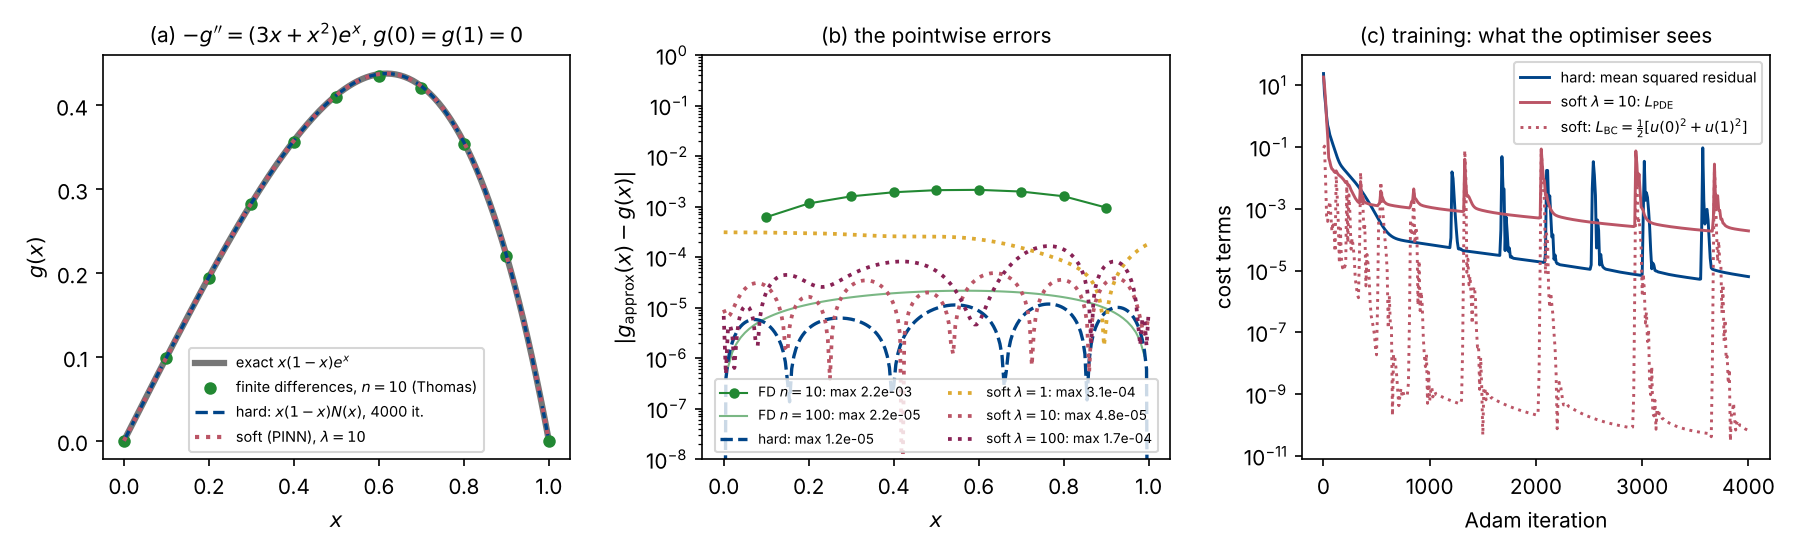

In [12]:
fig_poisson(hard, softs, rows)
Image("week43_poisson.png", width=1000)

**Reading the figure and the numbers.** With $\lambda=1$ the equation is
satisfied best but the solution is worst, because it is off by
$3\times10^{-4}$ at $x=0$ — a second-order equation with inexact boundary
values is inexact everywhere, and the error is largest exactly where the hard
solution is zero by construction. With $\lambda=100$ the boundary values are
as good as with $10$ but $L_{\mathrm{PDE}}$ is forty times the hard residual:
the gradient of $\lambda L_{\mathrm{BC}}$ dominates and one learning rate
cannot serve both terms (conditioning, Section 4.5; Table 9.1). The best soft
solution is four times worse than the hard one, and we had to try three
values of $\lambda$ to find it. Where a trial solution exists, it is free and
exact; where it does not — curved boundaries, inverse problems — the soft
version is the one we have.

**Pause and think.** Why does Thomas' algorithm need no pivoting, and what
happens to its cost for the Poisson equation in two dimensions? *(The
discrete Laplacian is symmetric positive definite and diagonally dominant,
so the pivots never get small. In two dimensions the matrix is block
tridiagonal with bandwidth $n$, elimination fills the band, and the cost is
$O(n^4)$ for $n^2$ unknowns — where iterative methods and, for irregular
domains, the networks of Chapter 9 enter.)*

## Part 2: reading a binary classifier (Section 5.12)

A classifier with a sigmoid output gives a probability $p\in(0,1)$; to
classify we choose a threshold $t$ and declare $\tilde y=1$ if $p>t$. Nothing
in the training picked $t$ — $0.5$ is a convention. Once a decision is made,
every sample lands in one of four boxes, and every number people quote is a
function of those four counts.

### The confusion matrix: four counts, and what each one means (Eq. 5.67)

$$
\begin{array}{c|cc}
 & \text{predicted } 1 & \text{predicted } 0\\ \hline
\text{true } 1 & \mathrm{TP} & \mathrm{FN}\\
\text{true } 0 & \mathrm{FP} & \mathrm{TN}
\end{array}
$$

Rows are the truth, columns the decision. In the language of a screening
test: **TP** — has the condition, test says so (found); **FN** — has the
condition, test says healthy (*missed*, the dangerous error in screening);
**FP** — healthy, test says condition (a *false alarm*, costs a follow-up);
**TN** — healthy, left alone. The two off-diagonal entries are two different
errors with different costs. (Mind the layout: `sklearn.metrics.confusion_matrix`
puts class 0 first, rows true 0/1 and columns predicted 0/1, so TP is in the
lower right.)

**A worked example** we carry through this part: a test for a condition
with prevalence $\pi=2\%$, applied to 1000 people, gives
$\mathrm{TP}=15$, $\mathrm{FN}=5$, $\mathrm{FP}=40$, $\mathrm{TN}=940$.
Twenty people have the condition; the test finds fifteen and raises forty
false alarms. Next to it we keep the "test" that declares everybody healthy:
$0, 20, 0, 980$.

### The measures, and what each one means (Eqs. 5.68–5.70)

- **Accuracy** $=(\mathrm{TP}+\mathrm{TN})/n$: the fraction of decisions that
  were right, all samples alike. Our test: $0.955$; everybody healthy:
  $0.980$ — *higher*, while finding nobody. Writing $n_+=\mathrm{TP}+\mathrm{FN}$,
  $n_-=\mathrm{FP}+\mathrm{TN}$ and $\pi=n_+/n$,
  $$\mathrm{accuracy}=\frac{n_+}{n}\frac{\mathrm{TP}}{n_+}+\frac{n_-}{n}\frac{\mathrm{TN}}{n_-}
  =\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity},$$
  so with $\pi=0.02$ whatever the test does on the sick is invisible at the
  second decimal. Always compare an accuracy with the majority-class
  accuracy $\max(\pi,1-\pi)$, and quote the fraction of the *remaining*
  error removed, $1-(1-\mathrm{acc})/(1-p_0)$.
- **Recall** (sensitivity, true positive rate) $=\mathrm{TP}/(\mathrm{TP}+\mathrm{FN})$:
  *of those who have the condition, what fraction did we find?* The
  denominator is the truth; the number is about the misses. Our test:
  $15/20=0.75$.
- **Specificity** (true negative rate) $=\mathrm{TN}/(\mathrm{TN}+\mathrm{FP})$:
  of the healthy, how many were left alone? $940/980=0.959$; its complement,
  the false positive rate $0.041$, is the horizontal axis of the ROC curve.
- **Precision** (positive predictive value) $=\mathrm{TP}/(\mathrm{TP}+\mathrm{FP})$:
  *of those we flagged, what fraction really had it?* The denominator is our
  decision; the number is about the false alarms. $15/55=0.27$ — three of
  four people called back are healthy, because the condition is rare: 40
  false alarms out of 980 healthy people is only a 4% false positive rate.
  Lowering the threshold raises recall and lowers precision; which matters
  is a question about the application (screening wants recall, a spam filter
  precision).
- **$F_1$** $=2\,\mathrm{prec}\cdot\mathrm{rec}/(\mathrm{prec}+\mathrm{rec})=2m/(1+m/M)$
  with $m=\min$, $M=\max$ of the two, so $m\le F_1\le2m$: small whenever
  either is small — the reason for the harmonic mean (precision 1 and recall
  0.1: arithmetic mean 0.55, harmonic mean 0.18). Our test: $0.40$;
  everybody healthy: $0$. $F_1$ never looks at TN.
- **Balanced accuracy** $=\tfrac12(\mathrm{recall}+\mathrm{specificity})$:
  the accuracy the test would have on a balanced population. $0.855$ against
  $0.5$ for the coin-like empty rule.
- **MCC**, the Matthews correlation coefficient
  $(\mathrm{TP}\,\mathrm{TN}-\mathrm{FP}\,\mathrm{FN})/\sqrt{(\mathrm{TP}+\mathrm{FP})(\mathrm{TP}+\mathrm{FN})(\mathrm{TN}+\mathrm{FP})(\mathrm{TN}+\mathrm{FN})}$,
  is the Pearson correlation between the 0/1 labels and the 0/1 decisions
  (Section 2.4): $+1$ perfect, $0$ no relation, $-1$ perfectly wrong. It uses
  all four counts and is symmetric in the classes, so it is the one scalar
  that is hard to fool by imbalance: $0.436$ against $0$.

Accuracy ranks the two tests the wrong way round; every other measure ranks
them the right way, and each says something different. The cell below
computes all of them from the four counts and checks them against
`scikit-learn`.

### The ROC curve, the AUC and the precision–recall curve

Every threshold gives one confusion matrix, hence one point
$(\mathrm{FPR},\mathrm{TPR})$; sweeping $t$ from 1 to 0 traces the ROC curve
from $(0,0)$ to $(1,1)$. A perfect ranking passes through $(0,1)$, a random
one gives the diagonal. The area under it is the probability that a random
positive outscores a random negative: sort all $n$ scores, let $R_i$ be the
rank of the $k_i$th positive; it outranks $R_i-k_i$ negatives, so the number
of correctly ordered pairs is $\sum_i R_i-\tfrac12 n_+(n_++1)$ and
$$\mathrm{AUC}=\frac{\sum_{i\in\mathrm{pos}}R_i-\tfrac12n_+(n_++1)}{n_+n_-},$$
the Mann–Whitney statistic (tied scores get the average rank and count half
a pair), equal to the trapezoidal area under the curve. It depends only on
the ranking: not on $t$, and not on the prevalence (duplicate every positive
and TP and FN double together). A random ranking, or all scores equal, gives
$0.5$. The precision–recall curve comes from the same sweep and *does*
depend on the prevalence, since precision has FP in its denominator; its
floor is $\pi$.

### Why we optimise the cross entropy and report the rest

As a function of the parameters the accuracy is a staircase with zero
gradient wherever it exists, so no method of Chapter 4 can minimise it; the
same holds for precision, recall, $F_1$ and the AUC. The cross entropy is
the smooth surrogate, minimised *roughly* where the decisions are right. Two
samples, one positive and one negative, threshold 0.5: model A gives
$p=0.51$ and $0.49$ (accuracy 1, cross entropy 0.673); model B gives
$0.99$ and $0.60$ (accuracy 0.5, cross entropy 0.463). B has the lower
cross entropy and the lower accuracy. Train on the cross entropy; evaluate
with the matrix, the AUC and the measures above.

In [13]:
def confusion_matrix(y_true, y_pred):
    """Eq. (5.67): the four counts TP, FN, FP, TN for labels in {0, 1}; the positive class is 1."""
    y_true, y_pred = np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    return tp, fn, fp, tn


def classification_report(y_true, y_pred):
    """Every scalar summary is a function of the four counts: Eqs. (5.68)-(5.70) and a few more."""
    tp, fn, fp, tn = confusion_matrix(y_true, y_pred)
    n = tp + fn + fp + tn
    accuracy = (tp + tn) / n
    precision = tp / (tp + fp) if tp + fp else 0.0          # of those flagged positive, how many were?
    recall = tp / (tp + fn) if tp + fn else 0.0             # of the positives, how many did we find? (= TPR)
    specificity = tn / (tn + fp) if tn + fp else 0.0        # of the negatives, how many did we leave alone? (= 1 - FPR)
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    balanced = 0.5 * (recall + specificity)
    denom = np.sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = ((tp * tn - fp * fn) / denom) if denom else 0.0  # Matthews correlation coefficient: correlation of y and y_hat
    return dict(TP=tp, FN=fn, FP=fp, TN=tn, accuracy=accuracy, precision=precision, recall=recall,
                specificity=specificity, f1=f1, balanced_accuracy=balanced, mcc=mcc)


def roc_curve(y_true, scores):
    """False and true positive rates as the threshold sweeps down through every distinct score.

    Sorting the scores once gives every point of the curve in O(n log n):
    walking down the sorted list, each sample flagged positive adds one to
    TP (if it is a positive) or to FP (if it is a negative).
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]            # one point per distinct threshold
    tpr = np.r_[0.0, tp[last] / max(tp[-1], 1)]
    fpr = np.r_[0.0, fp[last] / max(fp[-1], 1)]
    thresholds = np.r_[np.inf, s[last]]
    return fpr, tpr, thresholds


def auc_trapezoid(fpr, tpr):
    """The area under the ROC curve by the trapezoidal rule."""
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2))


def roc_auc(y_true, scores):
    """The AUC as the probability that a random positive outranks a random negative (Section 5.12), from the ranks.

    Tied scores get the average of the ranks they span, so that a tie between
    a positive and a negative counts half a pair -- which is also what the
    trapezoidal rule does along a tie segment of the ROC curve.
    """
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    _, inv, cnt = np.unique(scores, return_inverse=True, return_counts=True)
    first = np.cumsum(cnt) - cnt + 1                  # rank of the first member of each tie group
    ranks = (first + (cnt - 1) / 2)[inv]              # average rank within the group
    n_pos = int(np.sum(y_true == 1))
    n_neg = len(y_true) - n_pos
    S = np.sum(ranks[y_true == 1]) - n_pos * (n_pos + 1) / 2
    return float(S / (n_pos * n_neg))


def precision_recall_curve(y_true, scores):
    """Precision and recall at every distinct threshold, from the same sorted sweep as the ROC curve."""
    y_true, scores = np.asarray(y_true).astype(int), np.asarray(scores, dtype=float)
    order = np.argsort(-scores, kind="mergesort")
    y, s = y_true[order], scores[order]
    tp, fp = np.cumsum(y == 1), np.cumsum(y == 0)
    last = np.r_[np.diff(s) != 0, True]
    precision = tp[last] / (tp[last] + fp[last])
    recall = tp[last] / max(tp[-1], 1)
    return np.r_[1.0, precision], np.r_[0.0, recall], s[last]


def threshold_sweep(y_true, scores, thresholds=np.linspace(0.01, 0.99, 99)):
    """Precision, recall and F1 of the decision 'score > t' for a grid of thresholds t."""
    rows = []
    for t in thresholds:
        r = classification_report(y_true, scores > t)
        rows.append((t, r["precision"], r["recall"], r["f1"], r["accuracy"]))
    return np.array(rows)


def confusion_matrix_multiclass(y_true, y_pred, n_classes):
    """C[i, j] = number of samples of true class i predicted as class j."""
    C = np.zeros((n_classes, n_classes), dtype=int)
    np.add.at(C, (np.asarray(y_true).astype(int), np.asarray(y_pred).astype(int)), 1)
    return C


def per_class_from_confusion(C):
    """Precision and recall of every class from the K x K matrix: each class against the rest."""
    tp = np.diag(C).astype(float)
    precision = tp / np.maximum(C.sum(axis=0), 1)
    recall = tp / np.maximum(C.sum(axis=1), 1)
    return precision, recall


In [14]:
# the worked screening example, from the four counts, checked against scikit-learn
tp, fn, fp, tn = 15, 5, 40, 940
y_true = np.r_[np.ones(tp + fn), np.zeros(fp + tn)]
y_pred = np.r_[np.ones(tp), np.zeros(fn), np.ones(fp), np.zeros(tn)]
y_empty = np.zeros_like(y_true)                       # "everybody healthy"
from sklearn import metrics as skm
for name, yp in (("our test", y_pred), ("everybody healthy", y_empty)):
    r = classification_report(y_true, yp)
    print(f"--- {name}: TP {r['TP']} FN {r['FN']} FP {r['FP']} TN {r['TN']}")
    print("  " + "  ".join(f"{k} {r[k]:.3f}" for k in ("accuracy", "precision", "recall", "specificity", "f1", "balanced_accuracy", "mcc")))
    print(f"  sklearn: accuracy {skm.accuracy_score(y_true, yp):.3f} precision {skm.precision_score(y_true, yp, zero_division=0):.3f} "
          f"recall {skm.recall_score(y_true, yp):.3f} F1 {skm.f1_score(y_true, yp):.3f} "
          f"balanced {skm.balanced_accuracy_score(y_true, yp):.3f} MCC {skm.matthews_corrcoef(y_true, yp):.3f}")
pi = (tp + fn) / (tp + fn + fp + tn)
print(f"accuracy = pi*recall + (1-pi)*specificity = {pi * 0.75 + (1 - pi) * 940 / 980:.3f}")
# the two-sample example: lower cross entropy, lower accuracy
for name, p_pos, p_neg in (("model A", 0.51, 0.49), ("model B", 0.99, 0.60)):
    ce = -0.5 * (np.log(p_pos) + np.log(1 - p_neg))
    acc = 0.5 * ((p_pos > 0.5) + (p_neg <= 0.5))
    print(f"{name}: accuracy {acc:.1f}, cross entropy {ce:.3f}")

--- our test: TP 15 FN 5 FP 40 TN 940
  accuracy 0.955  precision 0.273  recall 0.750  specificity 0.959  f1 0.400  balanced_accuracy 0.855  mcc 0.436
  sklearn: accuracy 0.955 precision 0.273 recall 0.750 F1 0.400 balanced 0.855 MCC 0.436
--- everybody healthy: TP 0 FN 20 FP 0 TN 980
  accuracy 0.980  precision 0.000  recall 0.000  specificity 1.000  f1 0.000  balanced_accuracy 0.500  mcc 0.000
  sklearn: accuracy 0.980 precision 0.000 recall 0.000 F1 0.000 balanced 0.500 MCC 0.000
accuracy = pi*recall + (1-pi)*specificity = 0.955
model A: accuracy 1.0, cross entropy 0.673
model B: accuracy 0.5, cross entropy 0.463


### The example: is it a five?

Full MNIST, $y=1$ for the fives — $9.0\%$ of the training images and
$8.9\%$ of the test images, a deliberately imbalanced problem. Two
classifiers from Project 2, the week-41 code unchanged, ten epochs of SGD
with $M=100$, $\gamma=0.1$, seed 2026: logistic regression ($784\to1$, 785
parameters) and one hidden layer of 32 ReLU units ($784\to32\to1$, 25 153
parameters). The classifier that never says "five" scores an accuracy of
$0.911$ — the number every accuracy on this problem must be compared with.

In [15]:
POSITIVE_DIGIT = 5


def five_classifiers(epochs=10, batch_size=100, hidden=32, verbose=False):
    """Two binary classifiers on the full MNIST set with y = 1 for the fives; returns scores on the test set."""
    X_train, y_train, X_test, y_test = load_mnist()
    yb, ybt = (y_train == POSITIVE_DIGIT).astype(float), (y_test == POSITIVE_DIGIT).astype(float)
    out = {"y_test": ybt, "y_train": yb, "digits_test": y_test, "X_test": X_test,
           "prevalence_train": float(yb.mean()), "prevalence_test": float(ybt.mean())}
    for name, sizes, act in (("logistic regression", [784, 1], "sigmoid"),
                             (f"one hidden layer of {hidden}", [784, hidden, 1], "relu")):
        t0 = time.time()
        layers = create_layers(sizes, act, np.random.default_rng(2026))
        layers, hist = train(X_train, yb[:, None], layers, act, "binary", gamma=0.1, epochs=epochs,
                             batch_size=batch_size, X_test=X_test, y_test=ybt, verbose=verbose)
        p = predict(X_test, layers, act, "binary")[:, 0]
        out[name] = {"layers": layers, "history": hist, "time": time.time() - t0, "p_test": p,
                     "n_params": sum(W.size + b.size for W, b in layers),
                     "train_accuracy": accuracy(X_train, yb, layers, act, "binary"),
                     "test_accuracy": hist["test_accuracy"][-1]}
    return out


def analyse_binary(out, names=("logistic regression", "one hidden layer of 32")):
    """Every number of Part 2: reports at 0.5, ROC/AUC (hand and sklearn), F1-optimal threshold, cost-weighted threshold."""
    from sklearn.metrics import roc_auc_score, confusion_matrix as sk_confusion, f1_score
    y = out["y_test"]
    res = {"majority_accuracy": float(1 - y.mean())}
    for name in names:
        p = out[name]["p_test"]
        r = {"report_05": classification_report(y, p > 0.5)}
        fpr, tpr, thr = roc_curve(y, p)
        r["roc"] = (fpr, tpr, thr)
        r["auc_trapezoid"] = auc_trapezoid(fpr, tpr)
        r["auc_rank"] = roc_auc(y, p)
        r["auc_sklearn"] = float(roc_auc_score(y, p))
        r["pr"] = precision_recall_curve(y, p)
        sweep = threshold_sweep(y, p)
        r["sweep"] = sweep
        k = int(np.argmax(sweep[:, 3]))
        r["t_f1"], r["f1_max"] = float(sweep[k, 0]), float(sweep[k, 3])
        r["report_f1"] = classification_report(y, p > r["t_f1"])
        # a screening-type choice: a missed five costs five times a false alarm
        costs = [(t, 5 * classification_report(y, p > t)["FN"] + classification_report(y, p > t)["FP"]) for t in sweep[:, 0]]
        r["t_cost"] = float(min(costs, key=lambda c: c[1])[0])
        r["report_cost"] = classification_report(y, p > r["t_cost"])
        r["sk_confusion"] = sk_confusion(y, p > 0.5)          # rows true 0/1, columns predicted 0/1
        r["sk_f1"] = float(f1_score(y, p > 0.5))
        res[name] = r
    return res


In [16]:
t0 = time.time()
out = five_classifiers()
res = analyse_binary(out)
print(f"prevalence of fives: train {out['prevalence_train']:.4f}, test {out['prevalence_test']:.4f}")
print(f"the classifier that never says 'five': accuracy {res['majority_accuracy']:.4f}")
for name in ("logistic regression", "one hidden layer of 32"):
    o, r = out[name], res[name]
    print(f"--- {name}: {o['n_params']} parameters, {o['time']:.0f} s, train acc {o['train_accuracy']:.4f}, test acc {o['test_accuracy']:.4f}")
    rep = r["report_05"]
    print(f"  t = 0.5: TP {rep['TP']} FN {rep['FN']} FP {rep['FP']} TN {rep['TN']}  acc {rep['accuracy']:.4f} prec {rep['precision']:.4f} "
          f"rec {rep['recall']:.4f} spec {rep['specificity']:.4f} F1 {rep['f1']:.4f} bal.acc {rep['balanced_accuracy']:.4f} MCC {rep['mcc']:.4f}")
    print(f"  sklearn confusion_matrix (rows true 0/1, cols pred 0/1): {r['sk_confusion'].tolist()}, sklearn F1 {r['sk_f1']:.4f}")
    print(f"  AUC: trapezoid {r['auc_trapezoid']:.5f}, ranks {r['auc_rank']:.5f}, sklearn {r['auc_sklearn']:.5f}")
    rep = r["report_f1"]
    print(f"  F1-optimal threshold t = {r['t_f1']:.2f}: TP {rep['TP']} FN {rep['FN']} FP {rep['FP']} TN {rep['TN']}  acc {rep['accuracy']:.4f} "
          f"prec {rep['precision']:.4f} rec {rep['recall']:.4f} F1 {rep['f1']:.4f}")
    rep = r["report_cost"]
    print(f"  cost-weighted threshold (a missed five = 5 false alarms) t = {r['t_cost']:.2f}: TP {rep['TP']} FN {rep['FN']} FP {rep['FP']} TN {rep['TN']}  "
          f"acc {rep['accuracy']:.4f} prec {rep['precision']:.4f} rec {rep['recall']:.4f} F1 {rep['f1']:.4f}")
print(f"({time.time() - t0:.0f} s)")

prevalence of fives: train 0.0903, test 0.0892
the classifier that never says 'five': accuracy 0.9108
--- logistic regression: 785 parameters, 1 s, train acc 0.9710, test acc 0.9739
  t = 0.5: TP 693 FN 199 FP 62 TN 9046  acc 0.9739 prec 0.9179 rec 0.7769 spec 0.9932 F1 0.8415 bal.acc 0.8850 MCC 0.8308
  sklearn confusion_matrix (rows true 0/1, cols pred 0/1): [[9046, 62], [199, 693]], sklearn F1 0.8415
  AUC: trapezoid 0.97254, ranks 0.97254, sklearn 0.97254
  F1-optimal threshold t = 0.43: TP 719 FN 173 FP 82 TN 9026  acc 0.9745 prec 0.8976 rec 0.8061 F1 0.8494
  cost-weighted threshold (a missed five = 5 false alarms) t = 0.28: TP 772 FN 120 FP 186 TN 8922  acc 0.9694 prec 0.8058 rec 0.8655 F1 0.8346
--- one hidden layer of 32: 25153 parameters, 4 s, train acc 0.9945, test acc 0.9932
  t = 0.5: TP 841 FN 51 FP 17 TN 9091  acc 0.9932 prec 0.9802 rec 0.9428 spec 0.9981 F1 0.9611 bal.acc 0.9705 MCC 0.9576
  sklearn confusion_matrix (rows true 0/1, cols pred 0/1): [[9091, 17], [51, 841]

In [17]:
def draw_confusion(ax, tp, fn, fp, tn, title):
    """A 2x2 confusion matrix in the layout of Eq. (5.67): rows true, columns predicted, positive class first."""
    M = np.array([[tp, fn], [fp, tn]])
    ax.imshow(np.log10(M + 1), cmap="Blues", vmin=0, vmax=np.log10(M.sum()))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{M[i, j]}", ha="center", va="center", fontsize=13,
                    color="white" if M[i, j] > 0.3 * M.sum() else "black")
    ax.set_xticks([0, 1], ["pred. five", "pred. not"])
    ax.set_yticks([0, 1], ["true five", "true not"])
    for (i, j), lab in zip(((0, 0), (0, 1), (1, 0), (1, 1)), ("TP", "FN", "FP", "TN")):
        ax.text(j - 0.45, i - 0.42, lab, ha="left", va="top", fontsize=8,
                color="white" if M[i, j] > 0.3 * M.sum() else GREY)
    ax.set_title(title, fontsize=9)


def fig_confusion(out, res, names=("logistic regression", "one hidden layer of 32"), fname="week43_confusion.pdf"):
    fig, ax = plt.subplots(1, 3, figsize=(11, 3.4))
    for a, name in zip(ax[:2], names):
        r = res[name]["report_05"]
        draw_confusion(a, r["TP"], r["FN"], r["FP"], r["TN"],
                       f"{name}, $t=0.5$\nacc. {r['accuracy']:.4f}, prec. {r['precision']:.3f}, rec. {r['recall']:.3f}, $F_1$ {r['f1']:.3f}")
    r = res[names[1]]["report_f1"]
    draw_confusion(ax[2], r["TP"], r["FN"], r["FP"], r["TN"],
                   f"{names[1]}, $t={res[names[1]]['t_f1']:.2f}$ (max $F_1$)\nacc. {r['accuracy']:.4f}, prec. {r['precision']:.3f}, rec. {r['recall']:.3f}, $F_1$ {r['f1']:.3f}")
    fig.suptitle(f"MNIST test set, 'is it a five?': {int(out['y_test'].sum())} fives among 10 000 images; "
                 f"'never a five' scores accuracy {res['majority_accuracy']:.4f}", fontsize=10)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


def fig_metrics(out, res, names=("logistic regression", "one hidden layer of 32"), fname="week43_metrics.pdf"):
    y = out["y_test"]
    cols = {names[0]: GREY, names[1]: BLUE}
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
    p = out[names[1]]["p_test"]
    bins = np.linspace(0, 1, 41)
    ax[0].hist(p[y == 0], bins=bins, color=GREY, alpha=0.8, label=f"not a five ({int(np.sum(y == 0))})")
    ax[0].hist(p[y == 1], bins=bins, color=RED, alpha=0.8, label=f"a five ({int(np.sum(y == 1))})")
    ax[0].axvline(0.5, color="k", lw=1, ls="--")
    ax[0].set_yscale("log")
    ax[0].set_xlabel("output probability $p$ (one hidden layer)")
    ax[0].set_ylabel("test images")
    ax[0].legend(fontsize=7)
    ax[0].set_title("(a) what the classifier outputs", fontsize=10)
    ax[1].plot([0, 1], [0, 1], color="k", lw=0.8, ls="--", label="random ranking: AUC 0.5")
    for name in names:
        fpr, tpr, thr = res[name]["roc"]
        ax[1].plot(fpr, tpr, color=cols[name], lw=1.6, label=f"{name}: AUC {res[name]['auc_rank']:.4f}")
        k = np.searchsorted(-thr, -0.5)
        ax[1].plot(fpr[min(k, len(fpr) - 1)], tpr[min(k, len(tpr) - 1)], "o", color=cols[name], ms=5)
    ax[1].set_xlabel("false positive rate FP/(FP+TN)")
    ax[1].set_ylabel("true positive rate TP/(TP+FN) = recall")
    ax[1].set_xlim(-0.01, 0.3)
    ax[1].set_ylim(0.6, 1.005)
    ax[1].legend(fontsize=7, loc="lower right")
    ax[1].set_title("(b) ROC curves (zoomed); dots: threshold 0.5", fontsize=10)
    for name in names:
        prec, rec, _ = res[name]["pr"]
        ax[2].plot(rec, prec, color=cols[name], lw=1.6, label=name)
    ax[2].axhline(out["prevalence_test"], color=RED, lw=1, ls=":", label=f"always 'five': precision {out['prevalence_test']:.3f}")
    ax[2].set_xlabel("recall")
    ax[2].set_ylabel("precision")
    ax[2].set_ylim(0, 1.02)
    ax[2].legend(fontsize=7, loc="lower left")
    ax[2].set_title("(c) precision-recall curves", fontsize=10)
    sw = res[names[1]]["sweep"]
    ax[3].plot(sw[:, 0], sw[:, 1], color=BLUE, lw=1.6, label="precision")
    ax[3].plot(sw[:, 0], sw[:, 2], color=RED, lw=1.6, label="recall")
    ax[3].plot(sw[:, 0], sw[:, 3], color=GREEN, lw=1.6, label="$F_1$")
    ax[3].plot(sw[:, 0], sw[:, 4], color=GREY, lw=1.2, ls="--", label="accuracy")
    ax[3].axvline(res[names[1]]["t_f1"], color=GREEN, lw=0.8, ls=":")
    ax[3].axvline(0.5, color="k", lw=0.8, ls="--")
    ax[3].set_xlabel("decision threshold $t$ (one hidden layer)")
    ax[3].set_ylim(0.6, 1.01)
    ax[3].legend(fontsize=7, loc="lower center", ncol=2)
    ax[3].set_title(f"(d) the threshold is a choice ($F_1$ peaks at $t={res[names[1]]['t_f1']:.2f}$)", fontsize=9.5)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)


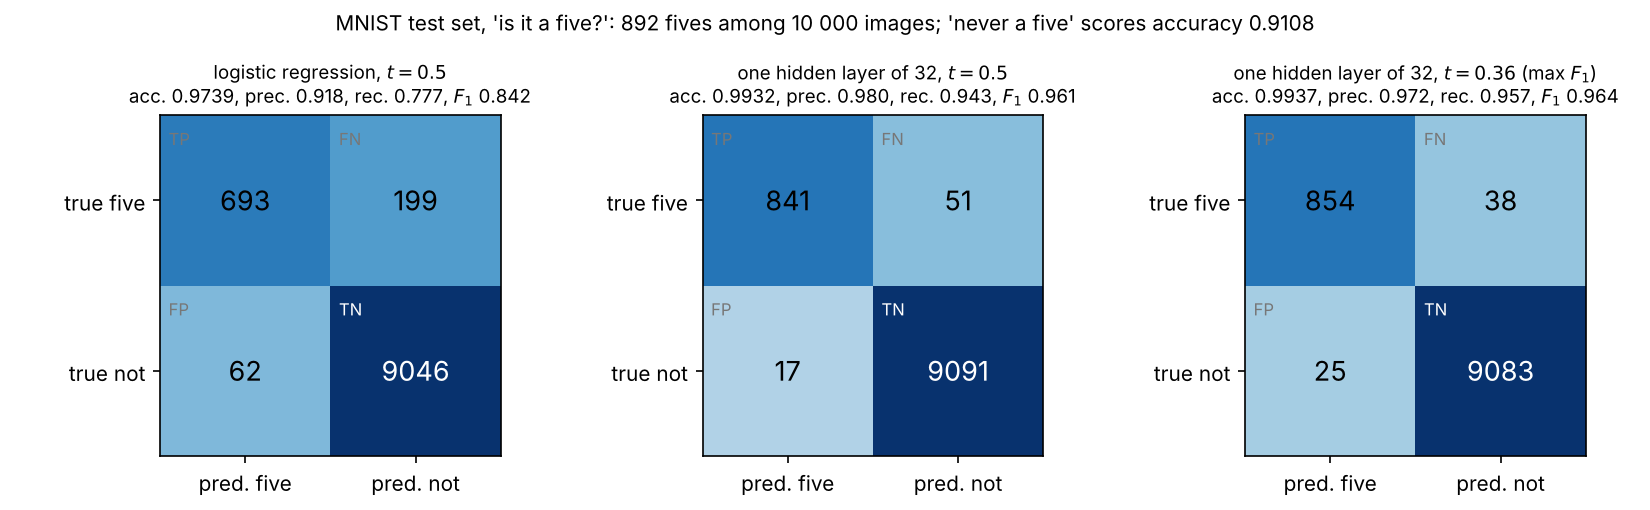

In [18]:
fig_confusion(out, res)
Image("week43_confusion.png", width=950)

**Logistic regression**: $97.4\%$ accuracy sounds good; the matrix says it
misses 199 of the 892 fives (recall $0.78$) while the 62 false alarms keep
the precision at $0.92$. Against the free $91.1\%$ it has removed $71\%$ of
the remaining error. **One hidden layer**: 51 missed, 17 false alarms,
recall $0.94$, precision $0.98$, $F_1=0.961$; $92\%$ of the error left by
the majority rule is gone. The third panel is the same network with the
threshold moved to $0.36$: 13 more fives found for 8 more false alarms, the
best $F_1$ — same model, different decision.

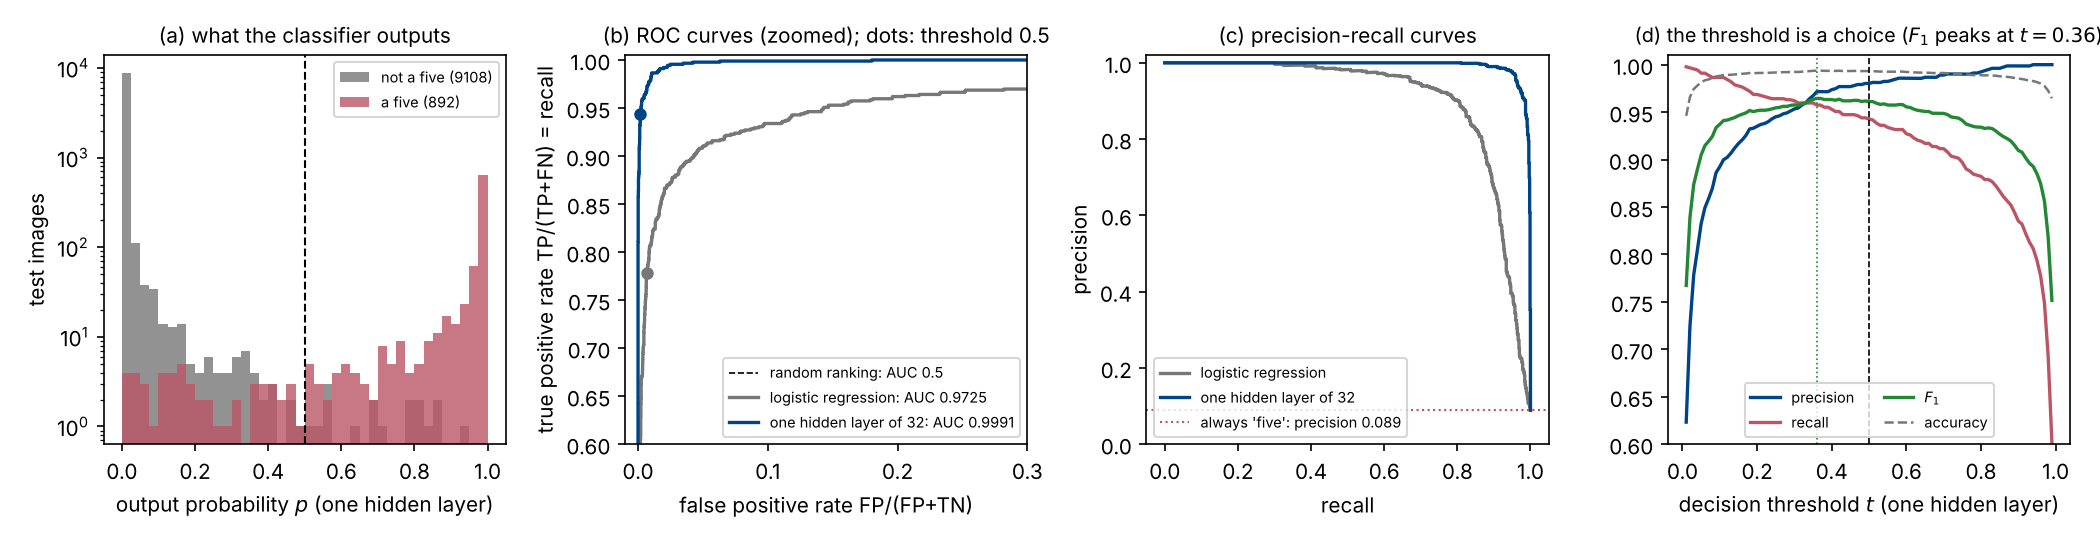

In [19]:
fig_metrics(out, res)
Image("week43_metrics.png", width=1100)

**The four pictures.** (a) The network's output by class: most images sit
at $p\approx0$ or $p\approx1$, and the errors live in the thin middle. (b)
The ROC curves, zoomed to the corner that matters: at a false positive rate
of $1\%$ the network has found $98\%$ of the fives, logistic regression
$82\%$. (c) Logistic regression cannot keep precision above $0.9$ beyond a
recall of $0.8$; the network holds $0.97$ to $0.96$. (d) Precision, recall
and $F_1$ against $t$ for the network: the accuracy is flat and useless as a
guide, $F_1$ peaks at $t=0.36$, and the two curves cross — there is no $t$
that is best for both.

**Choosing the threshold is choosing what an error costs.** Decide, before
looking at the test set, what a false negative costs relative to a false
positive; choose $t$ on validation data to minimise that cost (or to
maximise $F_1$); report the confusion matrix at that $t$ together with the
AUC, which does not depend on it. If a missed five costs five false alarms,
the network's threshold moves to $0.11$: recall $0.986$, precision $0.90$,
and the accuracy goes *down* while the recall goes up. Moving $t$ moves
along the ROC curve; it cannot lift the curve — the 12 fives still missed at
$t=0.11$ are ranked below 98 non-fives, and no decision rule fixes a
ranking.

**Pause and think.** The threshold moved from $0.5$ to $0.11$: did the
classifier change? *(No: weights, probabilities, ranking, ROC curve, AUC and
PR curve are identical; only the operating point moved, and with it every
number computed from the four counts. The AUC and the curves evaluate the
model; the confusion matrix evaluates the model together with a decision
rule, and a report should say which rule.)*

### Ten classes: the confusion matrix of the softmax network

The $784\to100\to10$ ReLU network of weeks 41–42, twenty epochs. Each class
against the rest is a $2\times2$ matrix read off the big one: the row of a
class gives its recall, the column its precision. Project 2 asks for this
matrix and for its interpretation.

In [20]:
def softmax_network(epochs=20, hidden=100, batch_size=100, verbose=False):
    """The 784-100-10 ReLU softmax network of weeks 41 and 42, for the ten-class confusion matrix."""
    X_train, y_train, X_test, y_test = load_mnist()
    t0 = time.time()
    layers = create_layers([784, hidden, 10], "relu", np.random.default_rng(2026))
    layers, hist = train(X_train, one_hot(y_train, 10), layers, "relu", "softmax", gamma=0.1, epochs=epochs,
                         batch_size=batch_size, X_test=X_test, y_test=y_test, verbose=verbose)
    P = predict(X_test, layers, "relu", "softmax")
    yhat = np.argmax(P, axis=1)
    C = confusion_matrix_multiclass(y_test, yhat, 10)
    return {"layers": layers, "history": hist, "time": time.time() - t0, "P_test": P, "yhat": yhat, "y_test": y_test,
            "C": C, "test_accuracy": float(np.mean(yhat == y_test))}


def fig_confusion10(sm, fname="week43_confusion10.pdf"):
    C = sm["C"]
    prec, rec = per_class_from_confusion(C)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.15, 1]})
    off = C.astype(float).copy()
    np.fill_diagonal(off, np.nan)
    im = ax[0].imshow(off, cmap="Reds", vmin=0, vmax=np.nanmax(off))
    for i in range(10):
        for j in range(10):
            if i == j:
                ax[0].text(j, i, f"{C[i, j]}", ha="center", va="center", fontsize=7, color=BLUE, fontweight="bold")
            elif C[i, j] > 0:
                ax[0].text(j, i, f"{C[i, j]}", ha="center", va="center", fontsize=7,
                           color="white" if C[i, j] > 0.6 * np.nanmax(off) else "black")
    ax[0].set_xticks(range(10))
    ax[0].set_yticks(range(10))
    ax[0].set_xlabel("predicted digit")
    ax[0].set_ylabel("true digit")
    ax[0].set_title(f"(a) 784-100-10 softmax network, test accuracy {sm['test_accuracy']:.4f}\n"
                    f"diagonal in blue; colour = off-diagonal count", fontsize=9)
    fig.colorbar(im, ax=ax[0], fraction=0.046)
    w = 0.38
    ax[1].bar(np.arange(10) - w / 2, prec, w, color=BLUE, label="precision (column)")
    ax[1].bar(np.arange(10) + w / 2, rec, w, color=RED, label="recall (row)")
    ax[1].set_ylim(0.9, 1.0)
    ax[1].set_xticks(range(10))
    ax[1].set_xlabel("digit")
    ax[1].legend(fontsize=8, loc="lower left")
    ax[1].set_title("(b) each class against the rest, from the same matrix", fontsize=9)
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return prec, rec


ten classes, 784-100-10 ReLU softmax, 20 epochs: test accuracy 0.9763 (18 s)
confusion matrix (rows true, columns predicted):
[[ 967    0    0    1    0    4    2    1    3    2]
 [   0 1123    4    0    0    1    2    1    4    0]
 [   4    1 1008    3    2    0    2    7    5    0]
 [   0    0    8  984    0    5    0    3    5    5]
 [   1    0    2    1  947    1    5    3    3   19]
 [   3    1    0    6    1  870    4    1    2    4]
 [   5    3    2    0    2    6  938    0    2    0]
 [   1    4   10    3    0    0    0 1000    2    8]
 [   3    0    4    7    4    4    3    3  943    3]
 [   3    2    1    6    5    1    0    5    3  983]]
per-class precision: [0.9797 0.9903 0.9702 0.9733 0.9854 0.9753 0.9812 0.9766 0.9702 0.96  ]
per-class recall:    [0.9867 0.9894 0.9767 0.9743 0.9644 0.9753 0.9791 0.9728 0.9682 0.9742]
largest confusions (true -> predicted: count): 4 -> 9: 19, 7 -> 2: 10, 7 -> 9: 8, 3 -> 2: 8, 2 -> 7: 7, 8 -> 3: 7


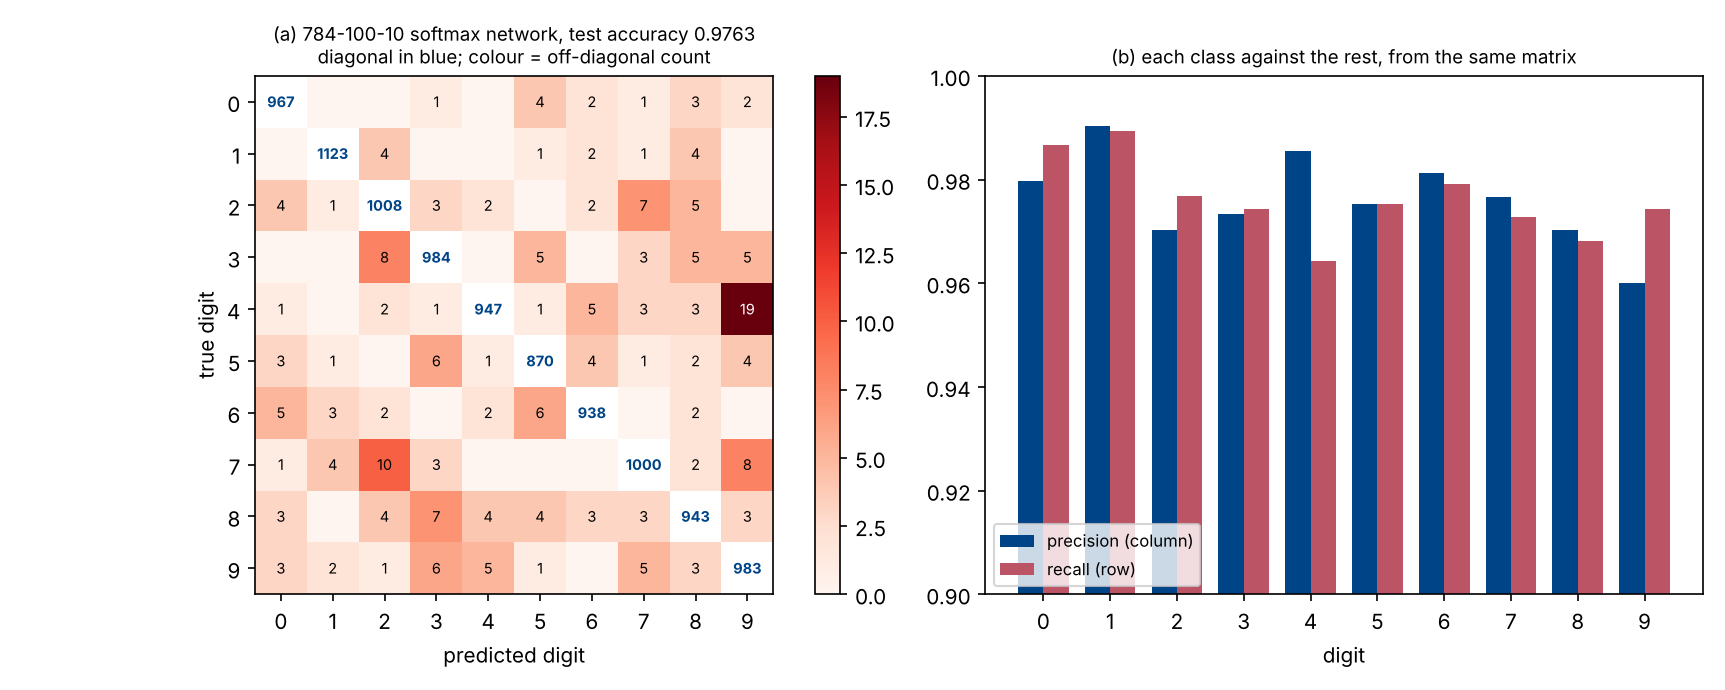

In [21]:
t0 = time.time()
sm = softmax_network()
prec, rec = fig_confusion10(sm)
print(f"ten classes, 784-100-10 ReLU softmax, 20 epochs: test accuracy {sm['test_accuracy']:.4f} ({sm['time']:.0f} s)")
print("confusion matrix (rows true, columns predicted):")
print(sm["C"])
print(f"per-class precision: {prec}")
print(f"per-class recall:    {rec}")
C_off = sm["C"].copy()
np.fill_diagonal(C_off, 0)
worst = np.dstack(np.unravel_index(np.argsort(-C_off.ravel())[:6], C_off.shape))[0]
print("largest confusions (true -> predicted: count): " + ", ".join(f"{i} -> {j}: {C_off[i, j]}" for i, j in worst))
Image("week43_confusion10.png", width=1000)

Test accuracy $0.9763$, the same number as in weeks 41 and 42 to the digit.
The matrix says *where* the 237 errors are: 19 fours read as nines, 10
sevens as twos, 8 sevens as nines, 8 threes as twos. Nines are the hardest
to be sure of (precision $0.960$), fours the easiest to miss (recall
$0.964$). The $4\to9$ and $7\to9$ confusions are what Part 3 is about.

**Every one of these numbers has an error bar.** An accuracy $\hat p$ on $n$
test images is a binomial proportion with standard error
$\sqrt{\hat p(1-\hat p)/n}$ (Eq. 2.24): $\pm0.0015$ for $0.9763$ on
$10\,000$ images, $\pm0.008$ for the recall of the fives on 892 images. Two
models that differ by less than that are not distinguishable by that test
set. In Project 2: the confusion matrix on the full test set, used once;
hyperparameters chosen on validation data; the accuracy next to its standard
error, the $10\%$ guess and the $\approx92\%$ of logistic regression.

**Pause and think.** An accuracy of $97.4\%$ — good or bad? *(On its own the
number says little. Next to it: the majority accuracy $0.911$, so $71\%$ of
the remaining error was removed, against $92\%$ for the network; the recall
$0.78$, more than one five in five missed; the AUC $0.9725$ against
$0.9991$, a worse ranking that no threshold rescues. The honest figure is
the pair of confusion matrices.)*

## Part 3: the first pieces of a convolutional network (Chapter 10)

### Why not a dense layer? (Section 10.1)

The network of Chapter 8 flattens a $28\times28$ image into 784 numbers;
permute the pixels of every image by one fixed permutation and it learns
exactly as well. A dense layer from a colour image of side $L$ to a hidden
layer of the same size has $9L^4$ weights (Eq. 10.1); a convolutional layer
with $K$ filters of extent $F$ on $C$ channels has $K(CF^2+1)$ (Eq. 10.2),
independent of the image size. The saving is bought by two assumptions about
the *data*: locality (an output depends on a small neighbourhood) and
parameter sharing (the same weights at every position).

### Convolution is polynomial multiplication, and a Toeplitz matrix (Sections 10.2.1–10.2.2)

$y(i)=(x*w)(i)=\sum_k w(k)\,x(i-k)$ (Eq. 10.4). Multiply
$p(t)=\alpha_0+\alpha_1t+\alpha_2t^2$ by
$s(t)=\beta_0+\beta_1t+\beta_2t^2+\beta_3t^3$ and collect terms: every
coefficient has the form $\delta_l=\sum_k\alpha_k\beta_{l-k}$ (Eq. 10.7).
Linearity in $\beta$ makes it a matrix, $(T_w)_{ij}=w_{i-j}$ (Eq. 10.8), with
constant descending diagonals — a Toeplitz matrix. Theorem 10.2: a matrix is
a convolution if and only if it is Toeplitz, so locality (banded) and sharing
(constant diagonals) are not merely convenient but exhaustive. We check the
three computations agree.

In [22]:
def toeplitz_matrix(w, n):
    """Eq. (10.8): the (n+m-1) x n matrix T_w with (T_w)_{ij} = w_{i-j}, so that T_w x = w * x (full convolution)."""
    m = len(w)
    T = np.zeros((n + m - 1, n))
    for i in range(n + m - 1):
        for j in range(n):
            if 0 <= i - j < m:
                T[i, j] = w[i - j]
    return T


def convolution_checks():
    """Polynomial multiplication = convolution = Toeplitz matrix (Eqs. 10.5-10.8), on the example of Section 10.2.1."""
    alpha = np.array([1.0, 2.0, 3.0])          # p(t) = 1 + 2t + 3t^2
    beta = np.array([4.0, -1.0, 0.5, 2.0])     # s(t) = 4 - t + 0.5 t^2 + 2 t^3
    delta_poly = np.polynomial.polynomial.polymul(alpha, beta)
    delta_conv = np.convolve(alpha, beta)
    T = toeplitz_matrix(alpha, len(beta))
    return {"alpha": alpha, "beta": beta, "polymul": delta_poly, "convolve": delta_conv, "toeplitz": T @ beta,
            "T": T, "agree": bool(np.allclose(delta_poly, delta_conv) and np.allclose(delta_conv, T @ beta))}


In [23]:
ck = convolution_checks()
print(f"polymul   {ck['polymul']}\nconvolve  {ck['convolve']}\nToeplitz  {ck['toeplitz']}   all agree: {ck['agree']}")
print("T_alpha =")
print(ck["T"])

polymul   [ 4.   7.  10.5  0.   5.5  6. ]
convolve  [ 4.   7.  10.5  0.   5.5  6. ]
Toeplitz  [ 4.   7.  10.5  0.   5.5  6. ]   all agree: True
T_alpha =
[[1. 0. 0. 0.]
 [2. 1. 0. 0.]
 [3. 2. 1. 0.]
 [0. 3. 2. 1.]
 [0. 0. 3. 2.]
 [0. 0. 0. 3.]]


### The convolutional layer, its arithmetic, and what libraries compute (Sections 10.2.4–10.3)

Libraries compute the cross-correlation $y(i)=\sum_k w(k)x(i+k)$ (Eq. 10.13)
and call it convolution — the network learns the reflected filter, so
nothing changes. In two dimensions with $C$ channels, $K$ filters each of
shape $C\times F\times F$, stride $S$ and padding $P$ (Eq. 10.16):

$$
Z(k,i,j)=\sum_{c=0}^{C-1}\sum_{m=0}^{F-1}\sum_{n=0}^{F-1}
X(c,\,Si+m-P,\,Sj+n-P)\,W(k,c,m,n)+b(k).
$$

Proposition 10.4: the output has depth $K$ and spatial size
$H_2=\lfloor(H_1-F+2P)/S\rfloor+1$ (Eq. 10.17), and the layer has
$K(CF^2+1)$ parameters (Eq. 10.18). Example 10.5: $32\times32\times3$ with
$K=10$, $F=5$, $S=1$, $P=0$ gives $28\times28\times10$ and 760 parameters,
against $2.4\times10^7$ for a dense layer with the same outputs.

In [24]:
def cross_correlate2d(X, W, stride=1, padding=0):
    """Eq. (10.15)/(10.16) for one channel and one filter: Y(i,j) = sum_{m,n} X(Si+m-P, Sj+n-P) W(m,n)."""
    if padding:
        X = np.pad(X, padding)
    F = W.shape[0]
    H2 = (X.shape[0] - F) // stride + 1
    W2 = (X.shape[1] - F) // stride + 1
    Y = np.zeros((H2, W2))
    for i in range(H2):
        for j in range(W2):
            Y[i, j] = np.sum(X[stride * i:stride * i + F, stride * j:stride * j + F] * W)
    return Y


def max_pool2d(X, F=2, S=2):
    """Eq. (10.21): the largest value in each F x F window, windows S apart; no parameters."""
    H2, W2 = (X.shape[0] - F) // S + 1, (X.shape[1] - F) // S + 1
    Y = np.zeros((H2, W2))
    for i in range(H2):
        for j in range(W2):
            Y[i, j] = np.max(X[S * i:S * i + F, S * j:S * j + F])
    return Y


def conv_arithmetic(H1, W1, C, K, F, S, P):
    """Proposition 10.1: output size, Eq. (10.17), and parameter count, Eq. (10.18)."""
    H2 = (H1 - F + 2 * P) // S + 1
    W2 = (W1 - F + 2 * P) // S + 1
    return H2, W2, K, K * (C * F * F + 1)



FILTERS = {"vertical edges": np.array([[-1.0, 0.0, 1.0], [-2.0, 0.0, 2.0], [-1.0, 0.0, 1.0]]),
           "horizontal edges": np.array([[-1.0, -2.0, -1.0], [0.0, 0.0, 0.0], [1.0, 2.0, 1.0]]),
           "blur (mean)": np.ones((3, 3)) / 9.0}

In [25]:
print(f"Example 10.5: 32x32x3, K=10, F=5, S=1, P=0 -> {conv_arithmetic(32, 32, 3, 10, 5, 1, 0)} (H2, W2, K, parameters); "
      f"dense layer with the same outputs: {32 * 32 * 3 * 28 * 28 * 10:.2e}")
print(f"MNIST 28x28x1, K=8, F=3, S=1, P=1 -> {conv_arithmetic(28, 28, 1, 8, 3, 1, 1)};  dense 784 -> 100: {784 * 100 + 100}")

Example 10.5: 32x32x3, K=10, F=5, S=1, P=0 -> (28, 28, 10, 760) (H2, W2, K, parameters); dense layer with the same outputs: 2.41e+07
MNIST 28x28x1, K=8, F=3, S=1, P=1 -> (28, 28, 8, 80);  dense 784 -> 100: 78500


### A five and three filters (Section 10.3)

Three *prescribed* $3\times3$ filters — the Sobel derivatives and the mean —
on a test image, with the four-line loop `cross_correlate2d` (checked
against `scipy.signal.correlate2d`); valid padding, so $28\to26$. Each map is
one feature map, Eq. (10.16) with $C=K=1$; a layer with $K=3$ filters
produces all three at once with $3\times(9+1)=30$ parameters. The
vertical-edge map is positive where the ink starts along a row and negative
where it ends; the horizontal one the same for the top and bottom strokes;
the blur is a low-pass filter. A trained network learns filters like the
first two from the data (Figure 10.8c).

(`convolution_demo` also computes a max-pooled map and checks the
translation equivariance of the feature map numerically — those are the
topics of next week's lecture, Sections 10.4–10.5, and we do not discuss
them here.)

In [26]:
def equivariance_check(X, W, shift=(2, 3)):
    """Theorem 10.3 numerically: shifting the input shifts the feature map, exactly, away from the border."""
    Y = cross_correlate2d(X, W)
    Xs = np.roll(np.roll(X, shift[0], axis=0), shift[1], axis=1)
    Ys = cross_correlate2d(Xs, W)
    Ys_back = np.roll(np.roll(Ys, -shift[0], axis=0), -shift[1], axis=1)
    m = max(shift) + 1
    interior = np.max(np.abs(Y[m:-m, m:-m] - Ys_back[m:-m, m:-m]))
    return float(interior), float(np.max(np.abs(Y - Ys_back)))


def convolution_demo(index=None, fname="week43_convolution.pdf"):
    """A test digit (the first five), its three feature maps, and the max-pooled vertical-edge map; checks against scipy."""
    from scipy.signal import correlate2d
    X_train, y_train, X_test, y_test = load_mnist()
    if index is None:
        index = int(np.argmax(y_test == POSITIVE_DIGIT))
    img = X_test[index].reshape(28, 28)
    maps = {name: cross_correlate2d(img, W) for name, W in FILTERS.items()}
    checks = {name: float(np.max(np.abs(maps[name] - correlate2d(img, W, mode="valid")))) for name, W in FILTERS.items()}
    pooled = max_pool2d(np.maximum(maps["vertical edges"], 0.0))     # not shown this week: pooling is Section 10.5
    equi = equivariance_check(img, FILTERS["vertical edges"])         # not shown this week: equivariance is Section 10.4
    fig, ax = plt.subplots(1, 4, figsize=(11.5, 3.6))
    ax[0].imshow(img, cmap="gray_r")
    ax[0].set_title(f"input $28\\times28$, label {y_test[index]}", fontsize=9)
    for a, (name, Y) in zip(ax[1:4], maps.items()):
        a.imshow(Y, cmap="RdBu_r", vmin=-np.max(np.abs(Y)), vmax=np.max(np.abs(Y)))
        a.set_title(f"{name}\n$3\\times3$ filter, valid: ${Y.shape[0]}\\times{Y.shape[1]}$", fontsize=9)
    for a in ax:
        a.set_xticks([])
        a.set_yticks([])
    fig.tight_layout()
    fig.savefig(fname)
    fig.savefig(fname.replace(".pdf", ".png"), dpi=150)
    plt.close(fig)
    return {"index": index, "label": int(y_test[index]), "scipy_checks": checks, "equivariance": equi,
            "shapes": {name: Y.shape for name, Y in maps.items()}, "pooled_shape": pooled.shape}


digit: test image 8 (label 5); feature maps {'vertical edges': (26, 26), 'horizontal edges': (26, 26), 'blur (mean)': (26, 26)}
agreement with scipy.signal.correlate2d: {'vertical edges': 4.440892098500626e-16, 'horizontal edges': 4.440892098500626e-16, 'blur (mean)': 2.220446049250313e-16}


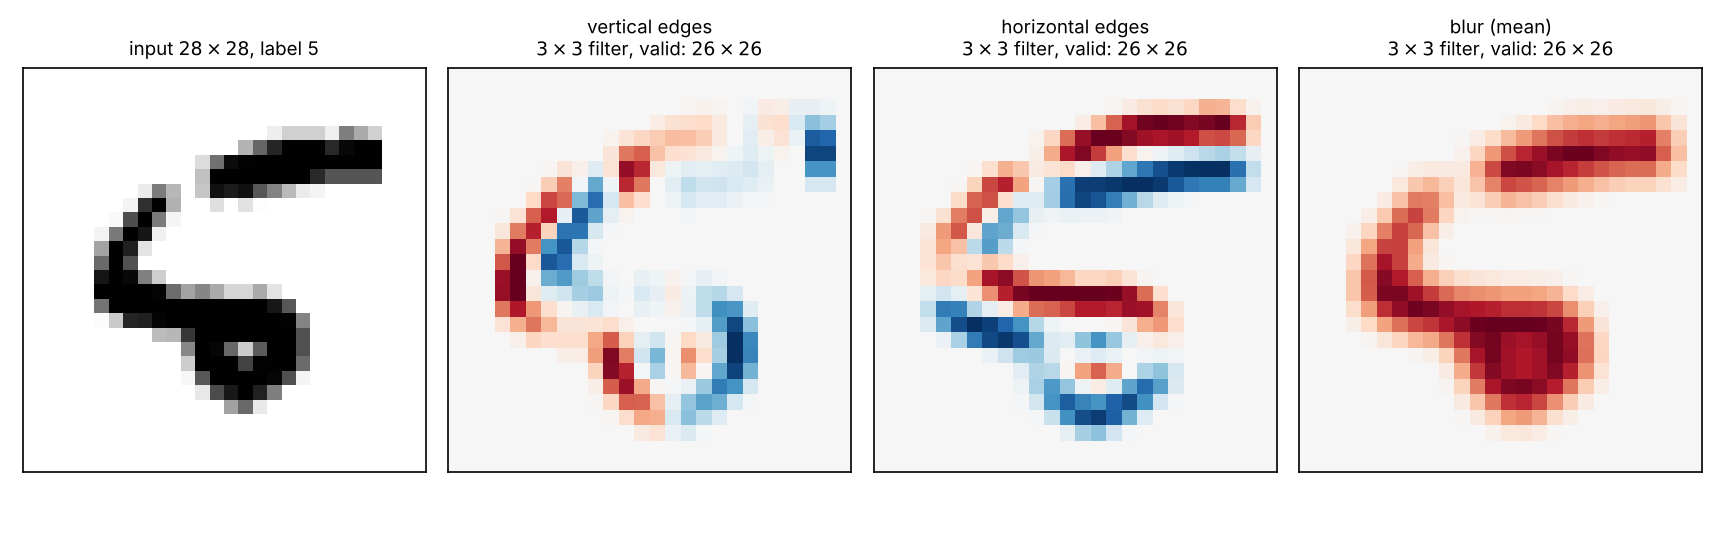

In [27]:
demo = convolution_demo()
print(f"digit: test image {demo['index']} (label {demo['label']}); feature maps {demo['shapes']}")
print(f"agreement with scipy.signal.correlate2d: {demo['scipy_checks']}")
Image("week43_convolution.png", width=1000)

**Pause and think.** Why is the map $26\times26$, and what does the
vertical-edge filter compute? *(Proposition 10.4 with $F=3$, $S=1$, $P=0$;
$P=1$ keeps $28\times28$, $S=2$ gives $13\times13$. The filter is a central
difference along a row, smoothed vertically: large where the intensity
changes along a row, i.e. at a vertical stroke, zero on a horizontal one.
The sign gives the direction of the change; a ReLU after the layer keeps one
direction, which is why a trained first layer ends up with opposed-sign
pairs of filters.)*

**Next week:** equivariance (Theorem 10.7 — convolution is the only linear
map that commutes with translation), pooling and the receptive field, the
backward pass through a convolution, the implementation from scratch, and
the experiment of Section 10.8 that shows what the architecture buys.

## Summary

- **One equation, three ways.** Hard constraints put the conditions in the
  ansatz, exact and free ($1.2\times10^{-5}$); soft constraints put them in
  the cost with a weight $\lambda$ to choose, four times worse at best, and
  are the only option when no ansatz exists. Thomas' algorithm solves the
  finite-difference system in $8n$ flops without pivoting: $2\times10^{-9}$
  in 11 ms at $n=10^4$. The network is not for problems that have one.
- **Reading a classifier.** Four counts, two kinds of error. Accuracy is
  $\pi\,\mathrm{recall}+(1-\pi)\,\mathrm{specificity}$ — blind to the rare
  class; recall asks about the misses, precision about the false alarms,
  $F_1$ is small if either is, MCC is their correlation. ROC and AUC judge
  the ranking, blind to threshold and prevalence; the PR curve is not. Train
  on the cross entropy, report the rest; choose $t$ from costs on validation
  data; report the matrix at that $t$, the AUC, and an error bar
  $\sqrt{\hat p(1-\hat p)/n}$.
- **Convolutional networks.** A dense layer on an image costs $9L^4$
  parameters and knows nothing about neighbours; locality and sharing give
  $K(CF^2+1)$, independent of the image size. Convolution is polynomial
  multiplication and a Toeplitz matrix; libraries compute cross-correlation;
  the layer (10.16) with its arithmetic (10.17)–(10.18); three prescribed
  filters on a five give a derivative and an average of the image, and a
  trained layer learns its own. Equivariance and pooling next week.